In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import  LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error,mean_absolute_error

In [4]:
df=pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [19]:
# 1. Preprocessing 
df = df.drop(columns=["Unnamed: 0", "key"],errors="ignore")
df=df.dropna()
df['pickup_datetime']=pd.to_datetime(df['pickup_datetime'])
df['hour']=df['pickup_datetime'].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

In [21]:
def haversine(lat1,lon1,lat2,lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = haversine(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
df = df.drop(columns=["pickup_datetime"])



In [22]:
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,4.475450
...,...,...,...,...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,10,28,10,2012,0.112210
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,1,14,3,2014,1.875050
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,0,29,6,2009,12.850319
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1,14,20,5,2015,3.539715


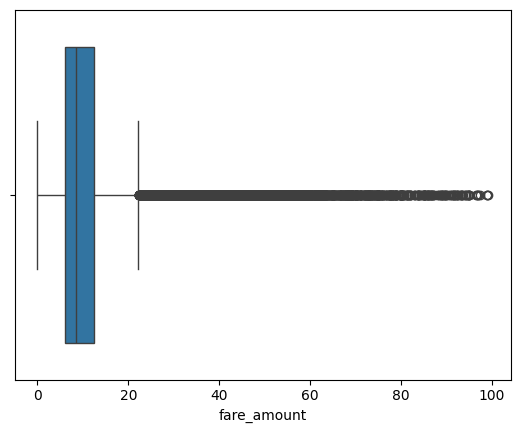

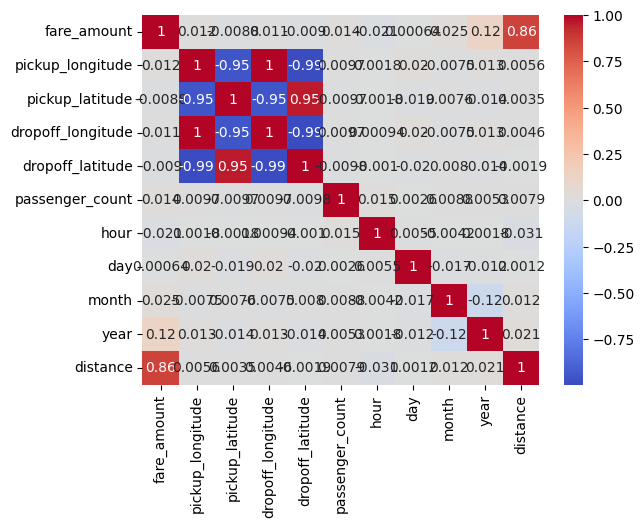

In [32]:
# 2. Outliers
sns.boxplot(x=df['fare_amount']); plt.show()

df = df[(df.fare_amount > 0) & (df.fare_amount < 100)]
df = df[(df.distance > 0) & (df.distance < 100)]
df = df[(df.passenger_count > 0) & (df.passenger_count <= 6)]

# 3 . correlation
sns.heatmap(df.corr(),annot=True,cmap="coolwarm"); plt.show()

In [36]:
# 4 . Models
X = df.drop("fare_amount", axis=1)
y=df['fare_amount']

In [39]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

models={"Linear":LinearRegression(),
        "Ridge":Ridge(1.0),
        "Lasso":Lasso(alpha=0.01)
        }


In [52]:
# 5. Evalution
for name,m in models.items():
    m.fit(x_train,y_train)
    p=m.predict(x_test)
    print(name)
    print("R2:",round(r2_score(y_test,p),4))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, p)), 4))
    print("MAE:", round(mean_absolute_error(y_test, p), 4))
    print("_"*32)

Linear
R2: 0.7791
RMSE: 4.3258
MAE: 2.248
________________________________
Ridge
R2: 0.7791
RMSE: 4.3258
MAE: 2.2479
________________________________
Lasso
R2: 0.7774
RMSE: 4.3422
MAE: 2.2533
________________________________
